# Indoor67 — Data exploration
Run from the repository root or use the path-detection cell below. This notebook uses **labeled training images only**. Never include the competition test images in validation.

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "dataset.py").is_file()
             and (p / "data" / "train.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository root or notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Repository:", ROOT)


Repository: c:\Users\Spencer\General\daml-aitp


In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from src.dataset import Indoor67Dataset, get_transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


## 1. Load the training manifest
`data/train.csv` contains `id,file_path,label`. Paths are relative to `data/images/`, with separate `train/` and `test/` folders. Labels come from the manifest, not folder names. Only labeled training images are used below.


In [3]:
DATA_DIR = ROOT / "data"
IMAGE_ROOT = DATA_DIR / "images"
MANIFEST = DATA_DIR / "train.csv"

df = pd.read_csv(MANIFEST, dtype=str).rename(
    columns={"id": "image_id", "file_path": "image_path"}
)
required = {"image_id", "image_path", "label"}
if not required.issubset(df.columns):
    raise ValueError(f"Training manifest must contain {sorted(required)} after renaming.")
if df.empty or df[list(required)].isna().any().any():
    raise ValueError("Training manifest is empty or contains missing IDs, paths, or labels.")
if df.image_id.duplicated().any() or df.image_path.duplicated().any():
    raise ValueError("Training manifest contains duplicate IDs or image paths.")
class_names = pd.read_csv(DATA_DIR / "classes.csv", dtype=str)["label"].tolist()
if len(class_names) != len(set(class_names)) or set(df.label) != set(class_names):
    raise ValueError("Training labels do not match the unique labels in classes.csv.")
# Keep manifest paths relative so saved splits work on other machines.
missing = [p for p in df.image_path if not (IMAGE_ROOT / p).is_file()]
if missing:
    raise FileNotFoundError(f"{len(missing)} training images missing under {IMAGE_ROOT}: {missing[:5]}")
print(f"Images: {len(df):,}; classes: {df.label.nunique()}")
display(df.head())


Images: 5,327; classes: 67


,image_id,image_path,label
0,train_000001,train/train_000001.jpg,florist
1,train_000002,train/train_000002.jpg,stairscase
2,train_000003,train/train_000003.jpg,tv_studio
3,train_000004,train/train_000004.jpg,bedroom
4,train_000005,train/train_000005.jpg,jewelleryshop


## 2. Inspect class distribution

count    67.000000
mean     79.507463
std       1.550886
min      76.000000
25%      78.000000
50%      79.000000
75%      80.000000
max      83.000000
Name: count, dtype: float64


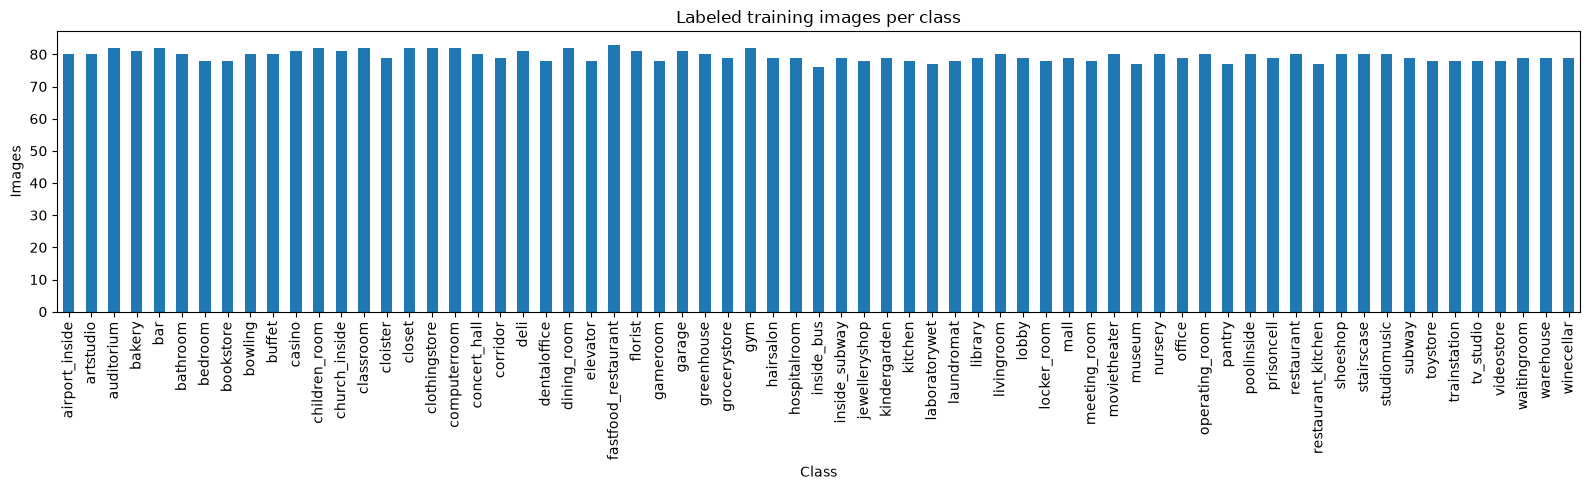

In [4]:
counts = df.label.value_counts().sort_index()
print(counts.describe())
fig, ax = plt.subplots(figsize=(16, 5))
counts.plot.bar(ax=ax)
ax.set(title="Labeled training images per class", xlabel="Class", ylabel="Images")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

## 3. Visualize a reproducible sample

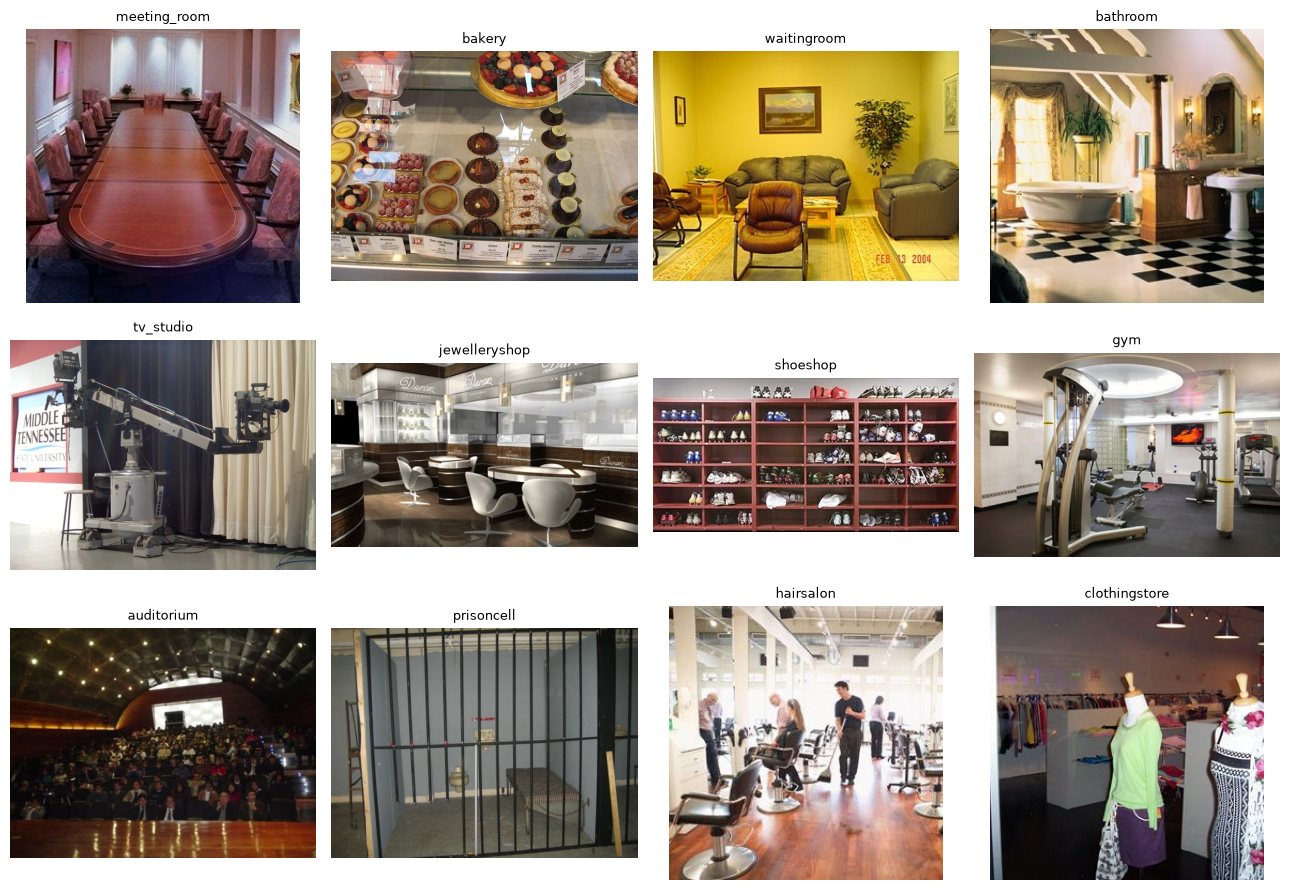

In [5]:
sample = df.sample(n=min(12, len(df)), random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    with Image.open(IMAGE_ROOT / row.image_path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(row.label, fontsize=9); ax.axis("off")
for ax in list(axes.flat)[len(sample):]: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Inspect image dimensions

,width,height
count,5327.000000,5327.000000
mean,391.318378,327.946687
std,110.055668,78.713795
min,130.000000,96.000000
25%,256.000000,256.000000
50%,400.000000,332.000000
75%,512.000000,384.000000
max,512.000000,512.000000


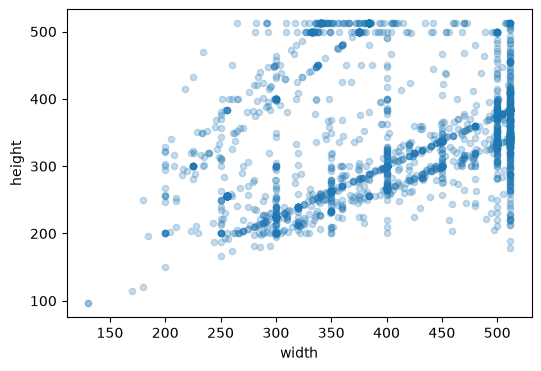

In [6]:
sizes = []
for p in df.image_path:
    with Image.open(IMAGE_ROOT / p) as im: sizes.append(im.size)
size_df = pd.DataFrame(sizes, columns=["width", "height"])
display(size_df.describe())
size_df.plot.scatter(x="width", y="height", alpha=0.25, figsize=(6, 4)); plt.show()

## 5. Create a reproducible stratified split
Use 80% of the labeled training rows for training and 20% for validation, with seed 42. Re-running recreates the same split for the same manifest. The saved CSV contains relative paths and split assignments; competition test images are never included.


In [7]:
train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df["label"]
)
split_df = df.copy()
split_df["split"] = "train"
split_df.loc[val_df.index, "split"] = "val"
assert set(train_df.image_id).isdisjoint(val_df.image_id)
assert set(train_df.label) == set(val_df.label) == set(class_names)
SPLIT_CSV = DATA_DIR / "validation_split.csv"
split_df.to_csv(SPLIT_CSV, index=False)
print(split_df.split.value_counts())
display(pd.crosstab(split_df.label, split_df.split))
print("Saved:", SPLIT_CSV)


split
train    4261
val      1066
Name: count, dtype: int64


split,train,val
label,,
airport_inside,64,16
artstudio,64,16
auditorium,66,16
bakery,65,16
bar,66,16
...,...,...
tv_studio,62,16
videostore,63,15
waitingroom,63,16


Saved: c:\Users\Spencer\General\daml-aitp\data\validation_split.csv


## 6. Test a PyTorch batch

In [8]:
# Use the same alphabetical label mapping as src.dataset.create_dataloaders.
class_names = sorted(df.label.unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
train_dataset = Indoor67Dataset(
    train_df, IMAGE_ROOT, class_to_idx=class_to_idx,
    transform=get_transforms(image_size=224, augment=True)
)
val_dataset = Indoor67Dataset(
    val_df, IMAGE_ROOT, class_to_idx=class_to_idx,
    transform=get_transforms(image_size=224)
)
train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0)
for name, loader in [("Train", train_loader), ("Validation", val_loader)]:
    images, labels = next(iter(loader))
    print(f"{name}: images {images.shape}, labels {labels.shape}")
    assert images.shape[1:] == (3, 224, 224)
    assert torch.isfinite(images).all()
    assert labels.min() >= 0 and labels.max() < len(class_names)
print("Classes:", len(class_names))


Train: images torch.Size([16, 3, 224, 224]), labels torch.Size([16])
Validation: images torch.Size([16, 3, 224, 224]), labels torch.Size([16])
Classes: 67


## 7. Notes for the next experiment
Record the image count, class count, class imbalance, and validation split. Reuse `data/validation_split.csv`, `IMAGE_ROOT`, and `class_to_idx` in later experiments to preserve this split and label mapping.
